# Week 11: NLP

In this workshop you build a **RAG system**, retrieval-augmented generation, over every NUS module:

- **Section 1 - Intro to NLP and LLMs:** why text is hard for computers, how an LLM writes, and where it gets things wrong.
- **Section 2 - Retrieval Engine:** embeddings, chunking and semantic search over the NUSMods data.
- **Section 3 - Generation + Evaluation:** let Gemini answer from the retrieved modules, then measure how good the retrieval is.

Run the cells from top to bottom. Cells marked **YOUR TURN** are for you to edit.

# Section 1 - Intro to NLP and LLMs

By the end of this workshop you will have built a **RAG system**: a search engine over every NUS module, connected to an LLM that answers questions using what the search finds. This section follows the slides:

1. **Reading text:** preprocessing, tokens and the token budget.
2. **Feature extraction:** keyword search, Bag of Words, TF-IDF and BM25.
3. **Hallucination and RAG:** ask Gemini about NUS modules, check its answers against the real data, and see why RAG is the fix.

## Setup

Run the cells in this part now, while everyone is arriving.

**In VS Code:** click **Select Kernel** (top right of the notebook) → **Python Environments**, and pick the virtual environment where you ran `pip install -r requirements.txt` (run it inside the `week-11-nlp` folder, where `requirements.txt` is). If VS Code asks to install `ipykernel`, click **Install**.

The first cell loads three things through `rag_utils.py`, a small helper file that all three sections share:

- `modules`: every module NUS offers in AY 2026-2027, taken from [NUSMods](https://nusmods.com). Each module is a Python dictionary with its code, title, description, workload and more. The organisers downloaded this in advance and saved it in `data/`, so the workshop does not depend on NUSMods being up.
- `embeddings`: one row of numbers per module. You will meet these in Section 2.
- `model`: `all-MiniLM-L6-v2`, a small model that turns text into numbers. It runs on your own CPU and needs no API key. The first run downloads it (about 90 MB).

In [266]:
# %pip install -q google-genai sentence-transformers numpy matplotlib
import json
import os
import re
import textwrap
import urllib.request
import warnings

os.environ["TRANSFORMERS_VERBOSITY"] = os.environ["HF_HUB_VERBOSITY"] = "error"  # hide harmless warnings
warnings.filterwarnings("ignore", message=".*HF_TOKEN.*")

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

import rag_utils
from rag_utils import build_chunk, keyword_search, search

modules, embeddings, model = rag_utils.load()
by_code = {module["moduleCode"]: module for module in modules}  # "CS4248" -> its record

print(f"{len(modules)} modules offered in AY {rag_utils.AY}, fetched from NUSMods on {rag_utils.FETCH_DATE}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

6552 modules offered in AY 2026-2027, fetched from NUSMods on 2026-10-10


In [267]:
import pandas as pd

# One row per module. workload = weekly hours of [lecture, tutorial, lab, project, preparation]
pd.DataFrame(modules).head(5)

,moduleCode,title,description,workload,faculty,department,moduleCredit,semesters,hasExam,prerequisite
0,ABM5001,Leadership in Biomedicine,Leadership is fundamental to the success of in...,"[3, 0, 0, 4, 3]",Yong Loo Lin Sch of Medicine,NUS Medicine Dean's Office,2,[2],False,NaN
1,ABM5002,Advanced Biostatistics for Research,This course serves as a concept-based introduc...,"[1.5, 0.5, 0, 0, 3]",Yong Loo Lin Sch of Medicine,NUS Medicine Dean's Office,2,[2],False,NaN
2,ABM5003,Biomedical Innovation & Enterprise,This elective aims to equip students with the ...,"[1.5, 1.5, 0, 3, 4]",Yong Loo Lin Sch of Medicine,NUS Medicine Dean's Office,4,[1],False,NaN
3,ABM5004,Capstone Project,This course encompasses research projects rele...,"[0, 0, 18, 2, 0]",Yong Loo Lin Sch of Medicine,NUS Medicine Dean's Office,8,"[1, 2]",False,NaN
4,ABM5005,Advanced Agile Project Management for Biomedic...,"The current world is volatile, uncertain, comp...","[4, 0, 0, 4, 2]",Yong Loo Lin Sch of Medicine,NUS Medicine Dean's Office,4,[1],False,NaN


### Connect Gemini

Each of you needs your **own** free API key: the free quota is counted per Google Cloud project, so 40 people sharing one key would run out within minutes.

> **Your Gemini API key (one-time, about 2 minutes)**
> 1. Go to **[aistudio.google.com/apikey](https://aistudio.google.com/apikey)**, sign in with a *personal* Google account, click **Create API key** and copy the key. It's free — **don't** set up billing, because that turns the free tier off for the project.
> 2. Paste the key between the quotes in the cell below, then run it.
>
> The key is saved inside the notebook file, so don't share or commit the notebook with your key in it.

The cell connects `ask_gemini` (from `rag_utils.py`), the one function we use to talk to Gemini. It sends your prompt and nothing else: no extra documents, and no Google Search. If the call fails, for example because the free quota has run out, it prints the reason and returns a saved answer instead of crashing.

You should see `Gemini says: ready`. If you see `Gemini call failed` instead, the message tells you why. The most common one is `API key not valid`: copy the key again and re-run the cell. If it still fails, raise your hand. You can follow the Gemini demos on the main screen in the meantime.

In [268]:
from rag_utils import ask_gemini

GEMINI_API_KEY = ""  # vscode will prompt you to enter this in a secure way, or you can hardcode it here if you prefer

rag_utils.connect_gemini(GEMINI_API_KEY)
print("Gemini says:", ask_gemini("Reply with exactly: ready"))

Gemini says: ready


## 1.1 Reading text

How does a computer read text? Computers only understand numbers, so we have to turn words into numbers. That is hard, because text is **messy** (punctuation, capital letters, codes like `CS3244`) and **ambiguous** (one word can mean different things, and different words can mean the same thing).

NLP deals with this through a pipeline. This section covers the first six steps, and Section 2 the last two:

**Raw text → Cleaning → Tokenization → Normalization → Chunking → Feature extraction** → Embedding → Retrieval

Our example all the way through is one real NUSMods description, the first sentence of **CS3244 Machine Learning**:

> This course introduces basic concepts and algorithms in machine learning and neural networks.

## 1.2 Preprocessing

Before a computer can count words, we clean the text up in three stages:

- **Cleaning:** remove punctuation and symbols.
- **Tokenization:** split into words.
- **Normalization:** make different forms of the same word look alike. That covers lowercasing, stopword removal (drop common words such as "this", "and", "in"), stemming (chop off word endings: `machine` → `machin`) and lemmatization (back to the dictionary form: `networks` → `network`).

These steps help methods that count words, such as BM25 in 1.4. MiniLM, the model we use in Section 2, does not need most of them: it lowercases by itself and has its own tokenizer.

## 1.3 Tokenization

A **token** is a fundamental chunk of text that a language model processes, and **tokenization** is splitting text into tokens. Common words are usually 1 token, while rare words and codes get split into smaller pieces, e.g. `CS3244` → `CS | 324 | 4`.

A model can only read a limited number of tokens at once: its **token budget**. Anything past the budget gets cut off, and the model never sees it. **Chunking** cuts long text into pieces that fit the budget. You will choose chunks yourself in Section 2.

Here is MiniLM's tokenizer reading the CS3244 sentence. Change `budget` and re-run to see where the sentence gets cut.

In [269]:
sentence = by_code["CS3244"]["description"].split(". ")[0] + "."
tokens = model.tokenizer.tokenize(sentence)
print(f"{len(tokens)} tokens:", tokens)

# Try it: change the budget, then re-run
budget = 10

print()
print(f"Read ({budget} tokens):", model.tokenizer.convert_tokens_to_string(tokens[:budget]))
print(f"Cut off ({len(tokens[budget:])} tokens):", model.tokenizer.convert_tokens_to_string(tokens[budget:]))
print(f"MiniLM's real budget: {model.max_seq_length} tokens")

14 tokens: ['this', 'course', 'introduces', 'basic', 'concepts', 'and', 'algorithms', 'in', 'machine', 'learning', 'and', 'neural', 'networks', '.']

Read (10 tokens): this course introduces basic concepts and algorithms in machine learning
Cut off (4 tokens): and neural networks.
MiniLM's real budget: 256 tokens


With a budget of 10, the model never finds out that CS3244 covers neural networks. Real budgets are bigger, but so is real text.

**YOUR TURN:** every model comes with its own tokenizer. Alter the words below and re-run to see how MiniLM splits them, then paste the same words into ChatGPT's tokenizer at [tiktokenizer.vercel.app](https://tiktokenizer.vercel.app/) and compare. Try other module codes, your name, Singlish, or another language.

**Think about it:** how does the model decide where to split?

In [270]:
# YOUR TURN: alter the words, then re-run
my_words = [
    "learning", "GPU", "CS3244", "NUSMods",      # from the slides
    "regularities", "self-learning", "CS2040S",  # from the CS3244 description, and one of its prerequisites
    "eﬃciency", "汉语拼音方案",                    # oddities from the FIN3702A and CL3211 descriptions
]

for word in my_words:
    print(f"{word:>15} -> {model.tokenizer.tokenize(word)}")

# Each token is really an ID number in the model's vocabulary
print()
print("Token IDs:", model.tokenizer.encode("machine learning and neural networks", add_special_tokens=False))

       learning -> ['learning']
            GPU -> ['gp', '##u']
         CS3244 -> ['cs', '##32', '##44']
        NUSMods -> ['nu', '##smo', '##ds']
   regularities -> ['regular', '##ities']
  self-learning -> ['self', '-', 'learning']
        CS2040S -> ['cs', '##20', '##40', '##s']
       eﬃciency -> ['[UNK]']
         汉语拼音方案 -> ['[UNK]', '[UNK]', '[UNK]', '[UNK]', '方', '[UNK]']

Token IDs: [3698, 4083, 1998, 15756, 6125]


### Subword encoding

Storing every whole word would take too many pieces, and still fail on a new word such as "NUSMods". Single letters can spell anything, but make text far too long. **Subwords** sit in between: break words into smaller pieces that can be reused.

- Common words stay whole: `course` → `[course]`.
- Rare words are built from known pieces: `CS3244` → `[CS | 324 | 4]`.

So the model can read new words with a fixed list of pieces. Two common ways to build that list:

- **Byte-Pair Encoding (BPE):** start from single letters, and keep gluing together the two pieces that appear side by side most often. On `learning`, `training` and `mining`, round 1 glues `i + n → in`, and round 2 glues `in + g → ing`. New words reuse the pieces: `coding` → `c | o | d | ing`. ChatGPT's tokenizer is a BPE tokenizer.
- **WordPiece:** BPE's cousin. Same idea, but BPE glues the most common pair, while WordPiece glues the pair that sticks together most (pieces that rarely show up apart). Pieces inside a word start with `##`: `GPU` → `[gp | ##u]`.

MiniLM uses WordPiece, which is where the `##` in your output comes from. It also lowercases everything first. `[UNK]` means **unknown**: the character is not in MiniLM's vocabulary at all. `eﬃciency` looks normal, but its "ﬃ" is one special character (probably copied from a PDF), so MiniLM cannot read the word. That is messy text in action.

## 1.4 Feature extraction

### The search process

RAG has to find the right modules first. The simplest way is **keyword search**: return every module whose title contains your exact words, like the search bar on NUSMods. It is exact, but it ignores similar modules we might want: "machine learning" finds CS3244 Machine Learning, but not AIS5103 Foundations of Deep Learning.

The idea: look at all the words in the description, not just the title. `keyword_search` (from `rag_utils.py`) does that, like Ctrl+F on every description.

**YOUR TURN:** change the query and compare the two searches.

In [271]:
def title_search(query):
    """Modules whose title contains the query, word for word."""
    return [module for module in modules if query.lower() in module["title"].lower()]


# YOUR TURN: change the query, then re-run
query = "machine learning"

for where, matches in [("titles", title_search(query)), ("descriptions", keyword_search(query))]:
    print(f'"{query}" in {where}: {len(matches)} modules')
    for match in matches[:5]:
        print(f"    {match['moduleCode']:<9} {match['title']}")

"machine learning" in titles: 61 modules
    AIS5102   Practical Machine Learning for Scientific Discovery
    AIS5281   Machine Learning in a Research Project
    BMF5360   Machine Learning in Investments
    BN5212    Advanced Machine Learning for Biomedical Engineering and Sciences
    BT3017    Feature Engineering for Machine Learning
"machine learning" in descriptions: 5 modules
    AIS5102   Practical Machine Learning for Scientific Discovery
    BMF5360   Machine Learning in Investments
    BN5212    Advanced Machine Learning for Biomedical Engineering and Sciences
    BT3017    Feature Engineering for Machine Learning
    BT4240    Machine Learning for Predictive Data Analytics


The descriptions give many more matches, AIS5103 among them, but two problems remain. The matches come back in alphabetical order, not by relevance. And both searches compare characters: try `"how computers understand language"`, and neither finds anything, because no title or description contains that exact phrase.

### Bag of Words, TF-IDF and BM25

To rank modules, we turn each description into numbers (**feature extraction**) and give every module a score:

- **Bag of Words (BoW):** count each word in a description, so the text becomes a row of numbers. The score is the count of shared words. Problems: every word counts the same, so "course", which is in almost every description, still earns points; and word order is lost ("students teach tutors" = "tutors teach students").
- **TF-IDF:** TF (term frequency) is how often the word appears in this description, divided by its length. IDF (inverse document frequency) is how rare the word is across all descriptions: $\log_{10}(N \div \text{descriptions that have the word})$. TF × IDF is high for a word that is frequent here and rare elsewhere.
- **BM25 (Best Matching 25):** TF-IDF with two fixes. **Saturation:** the 10th "learning" adds much less than the 1st (`k1 = 1.2`). **Length:** long descriptions don't win just by having more words (`b = 0.75`).

The next cell scores every NUSMods description all three ways, with the same formulas as the tables on the slides.

In [272]:
from collections import Counter


def split_words(text):
    """Lowercase the text and split it into words."""
    return re.findall(r"[a-z0-9]+", text.lower())


bags = [Counter(split_words(module["description"])) for module in modules]  # one Bag of Words per module
lengths = np.array([sum(bag.values()) for bag in bags])                       # words in each description
has_word = Counter(word for bag in bags for word in bag)                      # descriptions that have each word


def word_scores(query, method="bm25", k1=1.2, b=0.75):
    """Score every description against the query with "bow", "tfidf" or "bm25"."""
    scores = np.zeros(len(modules))
    for word in split_words(query):
        count = np.array([bag[word] for bag in bags])
        idf = np.log10(len(modules) / has_word[word]) if has_word[word] else 0.0
        if method == "bow":
            scores += count
        elif method == "tfidf":
            scores += count / lengths * idf
        elif method == "bm25":
            scores += idf * count * (k1 + 1) / (count + k1 * (1 - b + b * lengths / lengths.mean()))
    return scores


def word_search(query, method="bm25", k=5):
    """Return the top k (module, score) pairs."""
    scores = word_scores(query, method)
    top = np.argsort(-scores)[:k]
    return [(modules[i], float(scores[i])) for i in top]

In [273]:
# YOUR TURN: change the query, then re-run
query = "machine learning course"

for method in ["bow", "tfidf", "bm25"]:
    print(method)
    for module, score in word_search(query, method):
        print(f"  {score:6.2f}  {module['moduleCode']:<9} {module['title']:<45} ({len(split_words(module['description']))} words)")

bow
   21.00  EBA5012   Predictive Analytics Lifecycle                (243 words)
   14.00  CS5562    Trustworthy Machine Learning                  (99 words)
   14.00  EE6934    Emerging Topics in AI and Deep Learning       (119 words)
   14.00  EE3703    Machine Learning with Applications            (94 words)
   12.00  DSS5104   Machine Learning and Predictive Modelling     (97 words)
tfidf
    0.28  SA4110C   Machine Learning Application Development      (17 words)
    0.28  SA4110    Machine Learning Application Development      (17 words)
    0.14  CS5562    Trustworthy Machine Learning                  (99 words)
    0.14  CG3201    Machine Learning and Deep Learning            (77 words)
    0.13  MA6225    Topics in Machine Learning                    (19 words)
bm25
    4.34  CS5562    Trustworthy Machine Learning                  (99 words)
    4.29  SA4110C   Machine Learning Application Development      (17 words)
    4.29  SA4110    Machine Learning Application Developmen

**How to read it:** look at the word counts in brackets. A typical description has about 90 words.

- **BoW** puts EBA5012 first, a 243-word description: long text repeats the query words more often.
- **TF-IDF** divides by the length, so short descriptions such as SA4110 (17 words) jump to the top.
- **BM25** caps what repeated words add and compares each length with the average, so long and short descriptions compete on fairer terms.

"course" adds almost nothing to TF-IDF and BM25: nearly every description has it, so its IDF is close to 0. Try your own query, such as `"how computers understand language"`. Do the three methods agree?

## 1.5 Hallucination

When we use an LLM to look something up, it might **not know the updated data**, or **invent fluent but untrue facts**. Two reasons:

- **Knowledge cutoff:** it only knows what it was trained on, up to a certain date.
- **Next-token prediction:** it writes one token at a time, picking what sounds likely, not what is true.

Confident answers that are wrong are called **hallucinations**. We will ask Gemini about NUS modules, giving it **no extra information**, and then **check its answer** against the real NUSMods data.

`verify` does the checking. It finds every module code in an answer, such as `CS3244`, and looks it up in this year's module list.

In [274]:
MODULE_CODE = re.compile(r"\b[A-Z]{2,4}\d{4}[A-Z]{0,2}\b")  # e.g. CS3244, CS2040S


def verify(answer):
    """Look up every module code in the answer in the real NUSMods data."""
    codes = list(dict.fromkeys(MODULE_CODE.findall(answer)))  # unique, in order
    for code in codes:
        real = by_code.get(code)
        if real:
            print(f"  ✅ {code:<9} real title: {real['title']}")
        else:
            print(f"  ❌ {code:<9} not offered in AY {rag_utils.AY}, or does not exist")
        said = next(line for line in answer.splitlines() if code in line)  # where Gemini mentioned it
        print(f"{'':15}Gemini wrote: {textwrap.shorten(re.sub(r'[*_#`|>]', '', said), 90)}")
    print()
    print(f"{sum(code in by_code for code in codes)} of {len(codes)} module codes are real.")

In [275]:
question = "Which NUS modules cover attention mechanisms? List the module codes and titles."

answer = ask_gemini(question)
display(Markdown(answer))
print("-" * 60)
verify(answer)

At the National University of Singapore (NUS), attention mechanisms—a foundational concept in modern deep learning, transformers, and Large Language Models (LLMs)—are primarily covered in Computer Science (CS) and Information Systems (IS) modules, particularly within the Machine Learning and Artificial Intelligence specializations. 

Here are the key NUS modules that cover attention mechanisms, based on their official descriptions and syllabi:

### **Undergraduate & Graduate Level Modules**

*   **CS4248** – Natural Language Processing
    *   *Focus:* Covers traditional NLP as well as modern deep learning approaches. It heavily features recurrent neural networks with attention, the Transformer architecture, and self-attention mechanisms.
*   **CS5446** – AI Planning and Decision Making (or related advanced AI electives) / *Note: Often overlaps with advanced ML.*
*   **CS5340** – Uncertainty Modeling in Artificial Intelligence (Covers probabilistic models, sometimes touching on attention-based graph neural networks).
*   **CS5242** – Neural Networks and Deep Learning
    *   *Focus:* This is the core deep learning module at NUS. It typically dedicates significant time to sequence modeling, covering Recurrent Neural Networks (RNNs), LSTMs, the **attention mechanism**, and the Transformer architecture.
*   **CS4268** / **CS5421** – Computer Vision / Deep Learning for Computer Vision
    *   *Focus:* Modern computer vision relies heavily on attention. These modules cover Vision Transformers (ViTs) and spatial/channel attention mechanisms (like SENet).

### **Data Science & Machine Learning (DSML Program)**
*   **DSA4211** – Deep Learning (or equivalent under the Data Science curriculum)
    *   *Focus:* Practical applications of deep learning, including NLP and computer vision architectures that utilize attention.

***

*Note: University syllabi are updated frequently to keep up with fast-moving AI advancements (like the rise of Transformers and LLMs). If you are currently a student, **CS5242 (Neural Networks and Deep Learning)** and **CS4248 (Natural Language Processing)** are your best and most direct bets for a deep, mathematical, and practical understanding of attention mechanisms.*

------------------------------------------------------------
  ✅ CS4248    real title: Introduction to Large Language Models
               Gemini wrote: CS4248 – Natural Language Processing
  ✅ CS5446    real title: Reinforcement Learning and Sequential Decision Making
               Gemini wrote: CS5446 – AI Planning and Decision Making (or related advanced AI electives) / Note: [...]
  ✅ CS5340    real title: Uncertainty Modelling in AI
               Gemini wrote: CS5340 – Uncertainty Modeling in Artificial Intelligence (Covers probabilistic [...]
  ✅ CS5242    real title: Neural Networks and Deep Learning
               Gemini wrote: CS5242 – Neural Networks and Deep Learning
  ✅ CS4268    real title: Quantum Computing
               Gemini wrote: CS4268 / CS5421 – Computer Vision / Deep Learning for Computer Vision
  ✅ CS5421    real title: Database Applications Design and Tuning
               Gemini wrote: CS4268 / CS5421 – Computer Vision / Deep Learning for Computer Vision
  

**How to read it:**

- ❌ means the code is not in this year's NUSMods data. Either the module does not exist, or it is not running this year.
- ✅ with a different title means the code is real, but Gemini attached the wrong module to it, or used an old name.
- ✅ with a matching title means Gemini got that one right. You only know because you checked.

### Without and with retrieval

Specific numbers are the easiest thing for an LLM to get plausibly wrong. NUSMods lists the weekly workload of every module in hours. We ask Gemini twice: once on its own, and once with the CS3244 entry from NUSMods pasted into the prompt.

In [276]:
module_code = "CS3244"
workload_question = (f"What is the weekly workload of NUS module {module_code} in hours, "
                     "as lecture / tutorial / lab / project / preparation?")
entry = build_chunk(by_code.get(module_code, {}))  # code, title, description and workload from NUSMods

print("WITHOUT RETRIEVAL:")
print(ask_gemini(workload_question))
print()
print("WITH THE NUSMODS ENTRY:")
print(ask_gemini(f"Answer using only this entry from NUSMods.\n\n{entry}\n\n{workload_question}"))
print()
print("NUSMODS SAYS:", rag_utils.format_workload(by_code.get(module_code, {}).get("workload")) or "(not listed)")

WITHOUT RETRIEVAL:
According to the official National University of Singapore (NUS) module description for **CS3244 (Machine Learning)**, the workload is traditionally broken down into **10 hours per week**. 

Here is the standard breakdown of the 10 hours:

*   **Lectures:** 3 hours per week (usually conducted as 2 classes of 1.5 hours each).
*   **Tutorials:** 1 hour per week (held bi-weekly or weekly depending on the semester structure, averaging out to about 1 hour).
*   **Labs:** 0 hours of formal lab sessions (coding is done independently for assignments and projects).
*   **Project / Assignments:** ~3 to 4 hours per week (CS3244 features a substantial group-based machine learning project and regular programming assignments).
*   **Preparation / Independent Study:** ~2 to 3 hours per week (reviewing lecture notes, reading assigned materials, and studying for quizzes/exams).

**Summary of the 10-Hour Workload:**
*   **Lectures:** 3 hrs
*   **Tutorials:** 1 hr
*   **Lab:** 0 hrs
* 

Without retrieval, the answer is confident, but it may be outdated or wrong: hours that look reasonable are exactly what next-token prediction produces. With the entry in front of it, Gemini only has to read the answer off, and you know where it came from: NUSMods. Hold on to that idea, because it is the core of 1.6. Try a module you have taken, such as `CS2040S` or `ST2334`.

**YOUR TURN:** ask Gemini your own question about NUS modules, then check it. Ask for module codes, so that `verify` has something to check. Some things to try:

- A topic from the CS3244 description: *"Which NUS modules teach neural networks?"*
- What comes next: *"Which NUS modules should I take after CS3244?"*
- Something that changes every year, to test the knowledge cutoff: *"Which modules are precluded for CS3244?"*

In [277]:
# YOUR TURN: ask your own question, then re-run
my_question = "Which NUS modules should I take after CS3244 Machine Learning? List the module codes and titles."

my_answer = ask_gemini(my_question)
display(Markdown(my_answer))
print("-" * 60)
verify(my_answer)

After completing **CS3244 Machine Learning**, your next steps in the National University of Singapore (NUS) Computer Science curriculum depend on your specific area of interest—whether you want to go deeper into theoretical foundations, explore specialized AI domains (like NLP or Computer Vision), or apply ML to systems and data engineering.

Here is a list of follow-up NUS modules categorized by sub-discipline, along with their prerequisites and focus areas.

### 1. Advanced Machine Learning & Deep Learning (Direct Continuations)
These modules build directly on the core concepts of CS3244, moving into modern neural networks, probabilistic modeling, and advanced algorithms.

*   **CS4246 AI: Planning and Decision Making**
    *   *Focus:* Reinforcement learning, automated planning, and decision-making under uncertainty. (Essential if you want to learn Deep Reinforcement Learning).
*   **CS4248 Natural Language Processing**
    *   *Focus:* Text processing, language models, transformer architectures (BERT, GPT), and semantic analysis. 
*   **CS5340 Uncertainty Modeling in Artificial Intelligence** *(Graduate-level, accessible to strong undergrads)*
    *   *Focus:* Probabilistic graphical models, Bayesian networks, and inference algorithms.
*   **CS5446 AI Planning and Decision Making** *(Graduate-level alternative/extension to CS4246)*
    *   *Focus:* Advanced reinforcement learning and sequential decision-making.

### 2. Computer Vision & Perception
If you are interested in image and video processing, generative AI for images, and spatial computing.

*   **CS4243 Computer Vision and Pattern Recognition**
    *   *Focus:* Image formation, feature extraction, object recognition, and foundational deep learning for computer vision (CNNs).
*   **CS5477 3D Computer Vision** *(Graduate-level)*
    *   *Focus:* 3D reconstruction, point clouds, neural radiance fields (NeRFs), and 3D deep learning.

### 3. Data Systems & MLOps (Machine Learning Engineering)
If you prefer the engineering, scaling, and deployment side of AI rather than just the algorithmic theory.

*   **CS4225 Big Data Systems for Data Science**
    *   *Focus:* Distributed data processing frameworks (Hadoop, Spark) required to train models on massive datasets.
*   **CS5228 Knowledge Discovery and Data Mining** *(Accessible to advanced undergrads)*
    *   *Focus:* Advanced data mining techniques, clustering, anomaly detection, and frequent pattern mining at scale.
*   **IS4242 Intelligent Systems Deployment** *(School of Computing - Information Systems)*
    *   *Focus:* MLOps, model monitoring, CI/CD for machine learning, and putting models into production.

### 4. Reinforcement Learning & Robotics
*   **CS5445 Autonomous Robots** *(Graduate-level)*
    *   *Focus:* Localization, mapping, motion planning, and applying ML/RL to physical robotic systems.

---

### Suggested Pathways based on Career/Interest Goals:

*   **If you want to work in Generative AI / LLMs:** Take **CS4248 (NLP)** followed by relevant graduate-level reading modules or ST modules in deep learning.
*   **If you want to work in Autonomous Driving / Robotics:** Take **CS4243 (Computer Vision)** and **CS4246 (Planning and Decision Making)**.
*   **If you want to be an ML Engineer (MLOps):** Take **CS4225 (Big Data Systems)** and **CS5228 (Data Mining)**.
*   **If you want to do AI Research:** Focus heavily on math modules (linear algebra, probability) and take **CS5340** and other 5000-level CS/ST courses. 

*Note: Always check NUSMods for the latest prerequisite updates, as module requirements can change.*

------------------------------------------------------------
  ✅ CS3244    real title: Machine Learning
               Gemini wrote: After completing CS3244 Machine Learning, your next steps in the National University [...]
  ✅ CS4246    real title: Reinforcement Learning and Sequential Decision Making
               Gemini wrote: CS4246 AI: Planning and Decision Making
  ✅ CS4248    real title: Introduction to Large Language Models
               Gemini wrote: CS4248 Natural Language Processing
  ✅ CS5340    real title: Uncertainty Modelling in AI
               Gemini wrote: CS5340 Uncertainty Modeling in Artificial Intelligence (Graduate-level, accessible [...]
  ✅ CS5446    real title: Reinforcement Learning and Sequential Decision Making
               Gemini wrote: CS5446 AI Planning and Decision Making (Graduate-level alternative/extension to CS4246)
  ✅ CS4243    real title: Computer Vision and Pattern Recognition
               Gemini wrote: CS4243 Computer Vision and Pattern 

## 1.6 The concept of RAG

**Retrieval-Augmented Generation (RAG)** is a framework that improves an LLM by connecting it to an external knowledge source. Ours is NUSMods.

Why not paste all of NUSMods into the prompt, the way we pasted the CS3244 entry? Because of the **token budget**: there are too many descriptions to fit into a single prompt. The cell below counts tokens with MiniLM's tokenizer, so treat the numbers as estimates.

In [278]:
chunks = [build_chunk(m) for m in modules]
chunk_lengths = [len(ids) for ids in model.tokenizer(chunks, verbose=False)["input_ids"]]

print(f"CS3244 alone: about {chunk_lengths[modules.index(by_code['CS3244'])]} tokens")
print(f"All {len(modules)} modules: about {sum(chunk_lengths):,} tokens, in every single prompt")
print(f"5 relevant modules: about {sum(chunk_lengths[:5]):,} tokens")

try:
    gemini_limit = rag_utils.gemini_client().models.get(model=rag_utils.GEMINI_MODEL).input_token_limit
    print(f"{rag_utils.GEMINI_MODEL} reads at most {gemini_limit:,} tokens per prompt")
except Exception:
    pass

CS3244 alone: about 123 tokens
All 6552 modules: about 864,566 tokens, in every single prompt
5 relevant modules: about 792 tokens
gemini-3.5-flash-lite reads at most 1,048,576 tokens per prompt


All of NUSMods would fill most of the budget, if it fits at all, and every single question would pay for it again, when an answer needs only a handful of modules. **So retrieve only the most relevant modules, and let the LLM answer from those.** A RAG system does that in seven steps:

| Step | What happens | Where |
|---|---|---|
| 1. Encode, 2. Index | the embedding model turns every module into a vector, and we store the vectors | Section 2 |
| 3. Encode, 4. Similarity search | the query becomes a vector too, and we find the module vectors closest to it | Section 2 |
| 5. Similar documents | the top few modules come back as the retrieved context | Section 2 |
| 6. Prompt | the question and the retrieved modules go to the LLM together | Section 3 |
| 7. Final response | the LLM answers from them, citing its sources | Section 3 |

## Recap

So far: text → tokens → word counts (Bag of Words, TF-IDF, BM25) → find the best-matching modules → give them to the LLM (RAG).

But keyword methods only match the exact same words. Search for "artificial intelligence": the CS3244 description talks about "machine learning and neural networks", so the two share 0 words, and BM25 scores CS3244 at 0, even though it is clearly an AI module.

In [279]:
cs3244 = modules.index(by_code["CS3244"])

print('BM25 score of CS3244 for "artificial intelligence":', word_scores("artificial intelligence", "bm25")[cs3244])
print('Ctrl+F matches for "how computers understand language":', len(keyword_search("how computers understand language")))

BM25 score of CS3244 for "artificial intelligence": 0.0
Ctrl+F matches for "how computers understand language": 5


Word counts still do not capture meaning, which is why we need **embeddings**. That is where Section 2 starts.

### If you're stuck

Run the cell below. It reloads everything Section 2 needs.

In [280]:
# Reloads the data, the embedding model and BM25 if anything above failed
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

import rag_utils
from rag_utils import ask_gemini, build_chunk, keyword_search, search

modules, embeddings, model = rag_utils.load()
by_code = {module["moduleCode"]: module for module in modules}

# From Section 1.4: BM25
def split_words(text):
    """Lowercase the text and split it into words."""
    return re.findall(r"[a-z0-9]+", text.lower())

bags = [Counter(split_words(module["description"])) for module in modules]
lengths = np.array([sum(bag.values()) for bag in bags])
has_word = Counter(word for bag in bags for word in bag)

def word_scores(query, method="bm25", k1=1.2, b=0.75):
    """Score every description against the query with "bow", "tfidf" or "bm25"."""
    scores = np.zeros(len(modules))
    for word in split_words(query):
        count = np.array([bag[word] for bag in bags])
        idf = np.log10(len(modules) / has_word[word]) if has_word[word] else 0.0
        if method == "bow":
            scores += count
        elif method == "tfidf":
            scores += count / lengths * idf
        elif method == "bm25":
            scores += idf * count * (k1 + 1) / (count + k1 * (1 - b + b * lengths / lengths.mean()))
    return scores

print(len(modules), "modules, embeddings", embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

6552 modules, embeddings (6552, 384)


# Section 2 - Retrieval Engine

Section 1 ended on a problem. Search for "artificial intelligence": the CS3244 description talks about "machine learning and neural networks", so the two share 0 words, and BM25 scores CS3244 at 0, even though it is clearly an AI module.

This section builds steps 1 to 5 of the RAG map from Section 1.6 (**Encode, Index, Encode, Similarity search, Similar documents**):

1. **Embedding:** turn text into numbers that capture meaning, and compare them.
2. **Chunking:** decide how much text goes into each set of numbers.
3. **Retrieval:** index every module once, then find the modules closest to a query.
4. **Limitations:** where semantic search still goes wrong.

Cells marked **YOUR TURN** are for you to edit. Everything else runs as it is.

In [281]:
# Two small helpers used throughout this section.
row_of = {module["moduleCode"]: i for i, module in enumerate(modules)}


def show(results):
    """Print (module, score) pairs, one per line."""
    for module, score in results:
        print(f"  {score:.2f}  {module['moduleCode']:<9} {module['title']}")

## 2.1 Embedding

### Sparse vs dense

Bag of Words, TF-IDF and BM25 all turn a text into a **sparse** vector: one column for every word in the vocabulary, and almost all of them 0. Two texts can only match on a column they both fill, so "artificial intelligence" and "machine learning" never meet.

An **embedding** is a **dense** vector: a fixed list of numbers, all of them in use, learned by a model instead of counted. No single number stands for a word. Texts with similar meanings get similar numbers, even when they share no words.

### Meet the data

Every module is one Python dictionary, fetched from NUSMods. Here is CS3244 from Section 1, exactly as it is stored:

In [282]:
for field, value in by_code["CS3244"].items():
    print(f"{field}: {value}")

moduleCode: CS3244
title: Machine Learning
description: This course introduces basic concepts and algorithms in machine learning and neural networks. The main reason for studying computational learning is to make better use of powerful computers to learn knowledge (or regularities) from the raw data. The ultimate objective is to build self-learning systems to relieve human from some of already-too-many programming tasks. At the end of the course, students are expected to be familiar with the theories and paradigms of computational learning, and capable of implementing basic learning systems.
workload: [2, 1, 0, 4, 3]
prerequisite: If undertaking an Undergraduate Degree THEN must have completed 1 of CS2040/CS2040C/CS2040DE/CS2040HS/CS2040S/YSC2229 at a grade of at least D AND must have completed 1 of EE2012/EE2012A/MA2116/MA2116T/MA2216/ST2131/ST2334/YSC2243 at a grade of at least D AND ( must have completed all of MA1511/MA1512 at a grade of at least D OR must have completed 1 of MA110

NUSMods has 21,160 modules on record for AY 2026-2027. We kept 6,552:

- **14,382 dropped** because they are not offered this year.
- **226 dropped** because the description is a placeholder such as "Not Available". With nothing to describe the module, its vector would come from the code and title alone.

### From text to numbers

We embed with `all-MiniLM-L6-v2`:

- **Small:** about 90 MB, and it runs on a laptop CPU.
- **Local:** no API key and no cost, because nothing is sent anywhere.
- **384 numbers out:** every text becomes exactly 384 numbers, whether it is two words or a whole description.

In [283]:
for text in ["artificial intelligence", by_code["CS3244"]["description"]]:
    vector = model.encode(text)
    print(f"{len(text.split()):>3} words in -> {vector.shape[0]} numbers out, starting {vector[:4].round(3)}")

  2 words in -> 384 numbers out, starting [-0.024  0.017  0.038 -0.009]
 81 words in -> 384 numbers out, starting [-0.025  0.036  0.003 -0.033]


The individual numbers mean nothing on their own. What matters is how close two vectors are.

### How it works

1. **Tokenize:** split the text into tokens, as in Section 1.3.
2. **Look up** a starting vector for each token.
3. **LM layers:** each token reads the others, so "bank" ends up with different numbers in "river bank" and in "bank account".
4. **Mean pool:** average all the token vectors into one vector for the whole text.

Averaging alone does not create meaning. The model was trained on millions of pairs of texts, pulling similar pairs together and pushing unrelated ones apart. That training is why similar meanings end up in similar positions.

Remember the **token budget**: MiniLM reads at most 256 tokens. Anything after that is silently dropped, which matters in 2.2.

### Cosine similarity

Picture each vector as an arrow. To compare two texts, we look at the angle between their arrows:

- **Same direction:** about 1, very similar.
- **Right angle:** about 0, unrelated.

This score is called **cosine similarity**. It is the **dot product** (multiply the two vectors position by position, then add everything up) divided by both lengths, so only the direction counts:

$$\cos(\theta) = \frac{A \cdot B}{\|A\| \, \|B\|}$$

In [284]:
def cosine(a, b):
    """Cosine similarity: the dot product divided by both lengths."""
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))


texts = [
    "artificial intelligence",
    "machine learning and neural networks",
    "Victorian novels and poetry",
]
vectors = model.encode(texts)

print(f'"{texts[0]}" vs "{texts[1]}":', round(cosine(vectors[0], vectors[1]), 2))
print(f'"{texts[0]}" vs "{texts[2]}":', round(cosine(vectors[0], vectors[2]), 2))

"artificial intelligence" vs "machine learning and neural networks": 0.6
"artificial intelligence" vs "Victorian novels and poetry": 0.1


The first pair shares 0 words, so BM25 would score it 0. Its vectors still point in a much closer direction than the second pair.

### YOUR TURN: how similar are these modules?

Every module already has a vector. They were computed in advance and stored in `embeddings`, where row `i` belongs to `modules[i]`. They were also scaled to length 1, so the plot below can skip the division in the formula. 2.3 explains why that helps.

Below are 10 modules from four areas, each compared with all the others. Add modules you know to `my_codes`, such as the ones you are taking this semester, and re-run. Do they land next to the modules you expect?

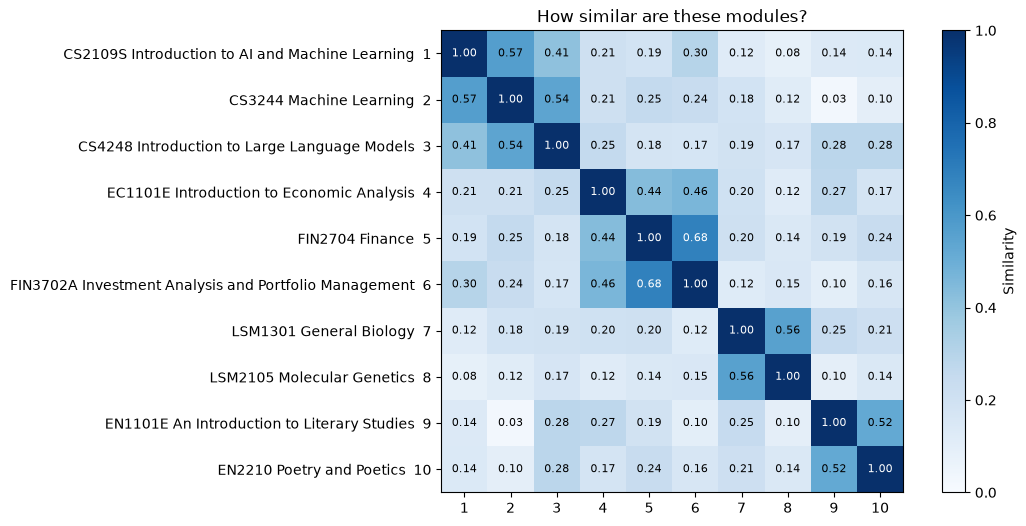

In [285]:
def plot_similarity(codes, title):
    """Heatmap of the similarity between every pair of modules."""
    rows = [row_of[code] for code in codes]
    labels = [f"{code} {modules[row]['title']}" for code, row in zip(codes, rows)]
    similarity = embeddings[rows] @ embeddings[rows].T
    count = len(codes)

    fig, ax = plt.subplots(figsize=(max(9, 0.6 * count + 4), max(6, 0.45 * count + 1.5)))
    image = ax.imshow(similarity, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(count), range(1, count + 1))
    ax.set_yticks(range(count), [f"{label}  {i + 1}" for i, label in enumerate(labels)])
    for i in range(count):
        for j in range(count):
            colour = "white" if similarity[i, j] > 0.6 else "black"
            ax.text(j, i, f"{similarity[i, j]:.2f}", ha="center", va="center", fontsize=8, color=colour)
    fig.colorbar(image, label="Similarity")
    ax.set_title(title)
    plt.show()


reference = [
    "CS2109S", "CS3244", "CS4248",     # AI
    "EC1101E", "FIN2704", "FIN3702A",  # economics and finance
    "LSM1301", "LSM2105",              # biology
    "EN1101E", "EN2210",               # literature
]

# YOUR TURN: add module codes, then re-run
my_codes = []  # for example ["CS2040S", "GEA1000"]

for code in my_codes:
    if code not in row_of:
        print(f"{code} is not offered in AY {rag_utils.AY}, so it is left out")
plot_similarity(reference + [code for code in my_codes if code in row_of], "How similar are these modules?")

**How to read it:** each cell compares two modules, and a darker cell means more similar. The diagonal is every module against itself, so it is always 1.00.

The darker squares along the diagonal are the four areas: AI, economics and finance, biology, and literature. Nobody told the model which faculty a module belongs to. It grouped them from the text alone.

Unrelated modules do not score 0. They mostly sit around 0.1 to 0.3, so read the scores as a ranking: related pairs score higher than unrelated ones.

**Think about it:** find CS4248, the large language models module. How does it score against the two literature modules, compared with FIN2704? What might the model be picking up?

## 2.2 Chunking

A **chunk** is one piece of text that gets its own vector. Real sources such as a handbook, a PDF or a website are too long to embed in one go, so we split them first. Two reasons:

- **Token budget:** MiniLM reads at most 256 tokens. Anything after that is silently cut off.
- **One vector has to summarise the whole chunk.** A vector for a 50-page handbook is about everything at once, so it is close to no particular question.

Too small hurts too. A chunk that holds one sentence, such as a workload line, has lost the module it belongs to. Aim for one self-contained idea per chunk.

Common ways to split:

- **Fixed size:** cut every N tokens.
- **Fixed size with overlap:** neighbouring chunks share some tokens, so a sentence cut at one boundary still appears whole in the next chunk.
- **Natural boundaries:** cut at sections, paragraphs or records. This is what we use.

NUSMods is already split at a natural boundary, and each module is short and self-contained, so **one module = one chunk**. It fits the token budget, it names the module, and it is a single idea. Let's check the budget part:

In [286]:
chunks = [build_chunk(module) for module in modules]
chunk_lengths = [len(ids) for ids in model.tokenizer(chunks, verbose=False)["input_ids"]]

print("CS3244 chunk:", chunk_lengths[row_of["CS3244"]], "tokens. The limit is", model.max_seq_length)
print("Typical chunk:", int(np.median(chunk_lengths)), "tokens")

too_long = sum(length > model.max_seq_length for length in chunk_lengths)
print(f"{too_long} of {len(modules)} chunks are over the limit and lose their ending")

CS3244 chunk: 123 tokens. The limit is 256
Typical chunk: 134 tokens
99 of 6552 chunks are over the limit and lose their ending


Only a small share of chunks get cut. When it happens, the end of the description and the workload are lost. That is why the code and title go first.

## 2.3 Retrieval

Retrieval runs as two pipelines:

| Pipeline | Steps on the map | When it runs |
|---|---|---|
| **Indexing** | 1. Encode, 2. Index | once, ahead of time |
| **Query** | 3. Encode, 4. Similarity search, 5. Similar documents | every search |

Steps 6 and 7, prompting the LLM with what we found, are Section 3.

### Indexing pipeline

**Documents → `build_chunk()` → `all-MiniLM-L6-v2` → Store.** Every module goes through `build_chunk`, the model embeds each chunk, and the vectors are stored. Embedding all 6,552 chunks takes minutes on a CPU, so it was done in advance, and the result is `embeddings`.

Large systems keep their vectors in a **vector database**, built to search millions of them quickly. For a few thousand modules, one numpy array is enough.

In [287]:
print(build_chunk(by_code["CS3244"]))
print()
print("Stored:", embeddings.shape, "= one row of 384 numbers for each module")

CS3244
Machine Learning
This course introduces basic concepts and algorithms in machine learning and neural networks. The main reason for studying computational learning is to make better use of powerful computers to learn knowledge (or regularities) from the raw data. The ultimate objective is to build self-learning systems to relieve human from some of already-too-many programming tasks. At the end of the course, students are expected to be familiar with the theories and paradigms of computational learning, and capable of implementing basic learning systems.
Workload: 2h lecture, 1h tutorial, 4h project, 3h preparation

Stored: (6552, 384) = one row of 384 numbers for each module


`build_chunk` (in `rag_utils.py`) joins four fields with line breaks: code, title, description and workload. NUSMods stores the workload as a list such as `[2, 1, 0, 4, 3]`, which tells an embedding model nothing, so we write it out in words first. Preparing text so that the model can use it is part of chunking.

### Query pipeline

1. Embed the query with the **same model** as the documents, so both live in the same space.
2. Compare the query with every module vector using cosine similarity.
3. Sort by score and take the top `k`.

Only the query gets embedded when a search comes in. That is why search is fast.

In [288]:
def my_search(query, k=5):
    query_vector = model.encode(query, normalize_embeddings=True)  # 1. embed the query
    scores = embeddings @ query_vector                             # 2. compare with every module
    top = np.argsort(-scores)[:k]                                  # 3. sort, take the top k
    return [(modules[i], float(scores[i])) for i in top]

That is the whole retrieval engine, and it is what `search` in `rag_utils.py` does.

**Why `embeddings @ query_vector` is cosine similarity:** with `normalize_embeddings=True`, every vector has length 1. The bottom of the cosine formula becomes 1, so cosine similarity is just the dot product. The line `embeddings @ query_vector` is one matrix multiplication that computes all 6,552 dot products at once. This only works because the module vectors were normalized too.

### Back to "artificial intelligence"

Here is the query from the end of Section 1, with BM25 and embeddings side by side.

In [289]:
query = "artificial intelligence"
cs3244 = row_of["CS3244"]

bm25 = word_scores(query, "bm25")
semantic = embeddings @ model.encode(query, normalize_embeddings=True)

for name, scores in [("BM25", bm25), ("Embeddings", semantic)]:
    print(name)
    for i in np.argsort(-scores)[:5]:
        marker = "   <-- CS3244" if i == cs3244 else ""
        print(f"  {scores[i]:.2f}  {modules[i]['moduleCode']:<9} {modules[i]['title']}{marker}")
    rank = int((scores > scores[cs3244]).sum()) + 1
    ties = int((scores == scores[cs3244]).sum()) - 1
    print(f"  CS3244: score {scores[cs3244]:.2f}, rank {rank}" + (f", tied with {ties} other modules" if ties else ""))
    print()

BM25
  4.73  IT1244    Artificial Intelligence: Technology and Impact
  4.51  PHM5005   AI and Machine Learning for Precision Medicine
  4.32  QF5315    Selected Topics in FinTech
  4.30  UTS2104   Intelligence and Singapore Society
  4.30  UTC2104   Intelligence and Singapore Society
  CS3244: score 0.00, rank 208, tied with 6344 other modules

Embeddings
  0.60  IT5005    Artificial Intelligence
  0.56  CS2109HS  Introduction to AI and Machine Learning
  0.55  CS3263    Foundations of Artificial Intelligence
  0.55  CS4263    Artificial Intelligence Principles
  0.55  EE2213    Introduction to Artificial Intelligence
  CS3244: score 0.44, rank 51



**How to read it:**

- **BM25** scores CS3244 at 0, tied with thousands of other modules at the very bottom. Its top results match the word "intelligence" without its meaning: UTS2104 Intelligence and Singapore Society is about human intelligence, not AI.
- **Embeddings** lift CS3244 from the bottom to about rank 50 of 6,552, the top 1%, even though the query and the description still share 0 words. Nearly every module above it is about AI too, most with "Artificial Intelligence" in the title, so they are a closer match for a two-word query.

That closes the gap from Section 1: embeddings match meaning, not words.

### YOUR TURN: try to break it

Semantic search won on that query. Now find where it fails.

**Predict first:** before you run the cell, guess which of these five queries will give a wrong or useless top result. Then run it and check your guesses.

In [290]:
breakers = [
    "hi",
    "CS2040S prereqs",
    "modules without a final exam",
    "lightest workload module",
    "pembelajaran mesin",  # "machine learning" in Indonesian/Malay
]

for query in breakers:
    print(query)
    show(my_search(query, k=3))
    print()

hi
  0.29  HY6770    Graduate Research Seminar
  0.27  GEX1024T  Universe, Big Bang, and Unsolved Mysteries
  0.26  SW1201    From AI to Authentic HI

CS2040S prereqs
  0.34  CS3245R   Information Retrieval
  0.34  CE5611QB  Precast Structural Concrete Design
  0.33  SA4101C   Software Analysis and Design

modules without a final exam
  0.43  MA3201    Algebra II
  0.42  MNO4752   Adv Independent Study in Leadership & Human Capital Mgt (2 MC)
  0.40  SW5660    Independent Study

lightest workload module
  0.50  MT5666    Industrial Attachment
  0.45  MLE5666   Industrial Attachment Module
  0.42  SWE5001G  Architecting Scalable Systems

pembelajaran mesin
  0.39  LAB3202   Bahasa Indonesia 4
  0.38  LAB2201   Bahasa Indonesia 2
  0.37  LAB1201   Bahasa Indonesia 1



In [291]:
# YOUR TURN: search with your own queries, and change k
my_query = "I want to learn how to invest"
k = 5

show(my_search(my_query, k))

  0.62  BMF5332   Foundation of Investments
  0.62  FIN4716   Equity Research Seminar
  0.60  FIN3702A  Investment Analysis and Portfolio Management
  0.60  FIN3702B  Investment Analysis and Portfolio Management
  0.60  BME5302   Investment Management


## 2.4 Limitations

Every one of the five queries breaks. Here is why:

| Query | Why it breaks | Top result |
|---|---|---|
| `hi` | small talk: there is nothing to find, but search still returns `k` modules | HY6770 Graduate Research Seminar |
| `CS2040S prereqs` | module codes carry no meaning: the tokenizer reads `cs ##20 ##40 ##s` | CS3245R Information Retrieval |
| `modules without a final exam` | negation: "without" barely moves the vector | MA3201 Algebra II, which has a final exam |
| `lightest workload module` | numbers and comparisons: the model cannot add up hours | MT5666 Industrial Attachment, 40 hours a week |
| `pembelajaran mesin` | MiniLM is trained mostly on English, so it matches the language, not the meaning | LAB3202 Bahasa Indonesia 4 |

The first row matters most: semantic search **always** returns `k` results. A score is a ranking, not a yes or no, so nothing tells you that the top result is junk.

Two fixes:

- **Exact matches** (codes, names, rare words): combine with BM25, which scores exact words. Running both and merging the two rankings is called **hybrid search**.
- **Junk results:** the generation step has to know when to say "I don't know". That is Section 3.

### Bonus: what goes into a chunk?

Skip this during the session, and come back to it afterwards.

`build_chunk` decides which fields go into each chunk, and that decides what a module can be found by. Changing it means embedding every module again, which takes minutes for all 6,552, so the cell below re-embeds the CS modules (about 160) only.

The cell starts with a shorter chunk: no code and no workload. For "machine learning", the scores go up and CS3244 Machine Learning moves up the list, because the chunk is now only about the topic.

**YOUR TURN:** choose your own fields and query. For example, add `"prerequisite"` and search for `"I have completed CS2040S, what next?"`. A field you add helps the questions about that field, and dilutes everything else.

In [292]:
# YOUR TURN: choose the fields and the query, then re-run
# Fields you can use: moduleCode, title, description, workload, prerequisite, faculty, department
my_fields = ["title", "description"]
my_query = "machine learning"

subset = [module for module in modules if module["moduleCode"].startswith("CS")]  # the CS modules only
default_vectors = embeddings[[row_of[module["moduleCode"]] for module in subset]]  # already computed
my_vectors = model.encode([build_chunk(module, my_fields) for module in subset], normalize_embeddings=True)

print("Default chunk:", list(rag_utils.DEFAULT_FIELDS))
show(search(my_query, embeddings=default_vectors, modules=subset))
print("My chunk:", my_fields)
show(search(my_query, embeddings=my_vectors, modules=subset))

Default chunk: ['moduleCode', 'title', 'description', 'workload']
  0.55  CS2109HS  Introduction to AI and Machine Learning
  0.55  CS5339    Theory and Algorithms for Machine Learning
  0.54  CS3264    Foundations of Machine Learning
  0.53  CS6216    Advanced Topics in Machine Learning
  0.46  CS3244    Machine Learning
My chunk: ['title', 'description']
  0.59  CS5339    Theory and Algorithms for Machine Learning
  0.58  CS6216    Advanced Topics in Machine Learning
  0.58  CS3244    Machine Learning
  0.58  CS2109HS  Introduction to AI and Machine Learning
  0.57  CS3264    Foundations of Machine Learning


## Recap

- **Embedding:** a model turns text into a dense vector, similar meanings land close together, and cosine similarity measures how close.
- **Chunking:** one module is one chunk. It fits the token budget, it names the module, and it is a natural boundary.
- **Indexing:** `build_chunk`, then the model, then store. We did it once, in advance: `embeddings`.
- **Query:** embed the query with the same model, take a dot product with every module, sort, and keep the top `k`. "artificial intelligence" now finds CS3244.
- **Limitations:** semantic search always returns `k` results, and struggles with exact matches, negation, numbers and other languages. The fixes are hybrid search and an LLM that knows when to say "I don't know".

Section 3 takes the modules returned by `search(query, k=5)` and hands them to Gemini.

### If you're stuck

Run the cell below. It reloads everything Section 3 needs.

In [311]:
# Reloads the data, the embedding model, Gemini and the helpers from Sections 1 and 2 if anything above failed
import re
import textwrap

from IPython.display import Markdown, display

import rag_utils
from rag_utils import ask_gemini, search

modules, embeddings, model = rag_utils.load()
by_code = {module["moduleCode"]: module for module in modules}
rag_utils.connect_gemini()

# From Section 1.5
MODULE_CODE = re.compile(r"\b[A-Z]{2,4}\d{4}[A-Z]{0,2}\b")  # e.g. CS4248, CS2103T

def verify(answer):
    """Look up every module code in the answer in the real NUSMods data."""
    codes = list(dict.fromkeys(MODULE_CODE.findall(answer)))  # unique, in order
    for code in codes:
        real = by_code.get(code)
        if real:
            print(f"  ✅ {code:<9} real title: {real['title']}")
        else:
            print(f"  ❌ {code:<9} not offered in AY {rag_utils.AY}, or does not exist")
        said = next(line for line in answer.splitlines() if code in line)  # where Gemini mentioned it
        print(f"{'':15}Gemini wrote: {textwrap.shorten(re.sub(r'[*_#`|>]', '', said), 90)}")
    print()
    print(f"{sum(code in by_code for code in codes)} of {len(codes)} module codes are real.")

# From Section 2
def show(results):
    """Print (module, score) pairs, one per line."""
    for module, score in results:
        print(f"  {score:.2f}  {module['moduleCode']:<9} {module['title']}")

print(len(modules), "modules, embeddings", embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

6552 modules, embeddings (6552, 384)


# Section 3 - Generation + Evaluation

Section 2 built the retriever. This section finishes the RAG pipeline from Section 1.6, then checks how well the retriever works:

1. **Generation:** paste the retrieved modules into the prompt (step 3, *augment*) and let Gemini answer from them (step 4, *generate*).
2. **Evaluation:** measure how often the retriever finds the right module, because the answer can only be as good as what was retrieved.

## 3.1 Generation

Two small functions do the augment step:

- `make_context` turns the `(module, score)` pairs from `search` into plain text, one numbered block per module.
- `build_prompt` wraps that text in instructions: answer **only** from the context, say so when the context is not enough, and cite module codes in square brackets.

In [312]:
def make_context(results):
    """Format retrieved (module, score) pairs as numbered text blocks."""
    blocks = []
    for rank, (module, score) in enumerate(results, start=1):
        lines = [
            f"[{rank}] {module['moduleCode']} - {module['title']}",
            f"Description: {module['description']}",
        ]
        workload = rag_utils.format_workload(module.get("workload"))
        if workload:
            lines.append(f"Workload: {workload}")
        if module.get("semesters"):
            lines.append(f"Semesters offered in AY {rag_utils.AY}: {', '.join(map(str, module['semesters']))}")
        if module.get("hasExam") is not None:
            lines.append(f"Has final exam: {'yes' if module['hasExam'] else 'no'}")
        lines.append(f"Retrieval similarity: {score:.3f}")
        blocks.append("\n".join(lines))
    return "\n\n".join(blocks) if blocks else "No modules were retrieved."


def build_prompt(question, context):
    """Wrap the question and the retrieved context in grounding instructions."""
    return f"""You are a helpful assistant answering questions about NUS modules.
Answer the user's question using only the supplied NUSMods context.

Rules:
- If the context does not contain enough evidence, say that the information is not available in the supplied context.
- Do not invent module codes, titles, prerequisites, workload hours, semesters, or exam details.
- When making a claim about a module, cite its module code in square brackets, e.g. [CS1231S].
- Keep the answer concise and distinguish explicit facts from uncertainty.
- The retrieval similarity score is not evidence that a claim is true.

Retrieved context:
{context}

User question: {question}

Answer:"""


def rag_answer(question, k=5, results=None, show_prompt=False):
    """Retrieve, augment, generate. Pass `results` to supply your own context."""
    if results is None:
        results = search(question, k=k)
    prompt = build_prompt(question, make_context(results))
    if show_prompt:
        print(prompt)
        print("-" * 60)
    answer = ask_gemini(prompt)
    display(Markdown(answer))
    return answer

### The same question, now with RAG

In Section 1.5, Gemini answered this question from memory, and `verify` caught the module codes it got wrong. Here is the exact prompt RAG sends for the same question. Gemini sees only this text.

In [313]:
question = "Which NUS modules cover attention mechanisms? List the module codes and titles."

print(build_prompt(question, make_context(search(question, k=5))))

You are a helpful assistant answering questions about NUS modules.
Answer the user's question using only the supplied NUSMods context.

Rules:
- If the context does not contain enough evidence, say that the information is not available in the supplied context.
- Do not invent module codes, titles, prerequisites, workload hours, semesters, or exam details.
- When making a claim about a module, cite its module code in square brackets, e.g. [CS1231S].
- Keep the answer concise and distinguish explicit facts from uncertainty.
- The retrieval similarity score is not evidence that a claim is true.

Retrieved context:
[1] PL3281A - Lab in Perception and Attention
Description: The focus of this lab will be perception and attention. Students will be introduced to the different methodologies used in cognitive research such as classical psychophysics, signal detection theory, and reaction time paradigms. Selected topics on perception and attention will be used to illustrate these methods.
Workloa

In [314]:
answer = rag_answer(question)
print("-" * 60)
verify(answer)

Based on the supplied context, the module that covers attention is:
- [PL3281A] Lab in Perception and Attention [1]

------------------------------------------------------------
  ✅ PL3281A   real title: Lab in Perception and Attention
               Gemini wrote: - [PL3281A] Lab in Perception and Attention [1]

1 of 1 module codes are real.


Every module code Gemini can cite now comes from the context, so `verify` should find each one in the real data. Compare this with the 1.5 result.

That fixes invented codes, but not missing ones. Look back at the retrieved modules in the prompt: are they about attention in neural networks, or attention in psychology? If the right module was not retrieved, Gemini cannot mention it. The answer is only as good as the context.

### Wrong context, confident answer

To see how much the answer depends on retrieval, keep the question and swap in modules retrieved for an unrelated topic.

In [297]:
wrong_results = search("modules about economics and financial markets", k=5)
show(wrong_results)
print("-" * 60)

wrong_answer = rag_answer(question, results=wrong_results)

  0.59  BMS5307   Financial Markets and Institutions
  0.59  EC5880    Topics in Economics
  0.59  BMD5301   Introduction to Finance for FinTech Professionals
  0.58  FE5213    Quantitative Macroeconomics and Finance with Python
  0.57  EC1101E   Introduction to Economic Analysis
------------------------------------------------------------


The information is not available in the supplied context.

**How to read it:** the prompt tells Gemini to say when the context is not enough. Check whether it did, or whether it stretched an economics module to fit a question about attention mechanisms. Either way, generation cannot recover from bad retrieval, which is why 3.2 measures the retriever on its own.

**YOUR TURN:** ask your own question. Set `show_prompt=True` to see exactly what Gemini received, and change `k` to give it more or fewer modules.

In [298]:
# YOUR TURN: ask your own question, then re-run
my_question = "Which NUS modules teach reinforcement learning? List the module codes and titles."

my_answer = rag_answer(my_question, k=5, show_prompt=False)
print("-" * 60)
verify(my_answer)

Based on the supplied context, the following modules teach reinforcement learning:

* [CEG5301] - Machine Learning with Applications [1]
* [IE5603] - Statistical Learning in Engineering II [2]
* [RB4301] - Robot Learning [3]
* [RB3301] - Introduction to Machine Intelligence [4]
* [CS5446] - Reinforcement Learning and Sequential Decision Making [5]

------------------------------------------------------------
  ✅ CEG5301   real title: Machine Learning with Applications
               Gemini wrote: [CEG5301] - Machine Learning with Applications [1]
  ✅ IE5603    real title: Statistical Learning in Engineering II
               Gemini wrote: [IE5603] - Statistical Learning in Engineering II [2]
  ✅ RB4301    real title: Robot Learning
               Gemini wrote: [RB4301] - Robot Learning [3]
  ✅ RB3301    real title: Introduction to Machine Intelligence
               Gemini wrote: [RB3301] - Introduction to Machine Intelligence [4]
  ✅ CS5446    real title: Reinforcement Learning and Sequential Decision Making
               Gemini wrote: [CS5446] - Reinforcement Learning and Sequential Decision Making [5]

5 of 5 module codes are real.


## 3.2 Evaluation

Now we evaluate how effectively our RAG system retrieves the correct NUS module for a user's question.

For each query, we specify the expected module code and compare it with the modules returned by our retrieval system.

We use two metrics:

- **Hit@5:** Measures the proportion of queries for which the correct module appears in the top five retrieved results.
- **Mean Reciprocal Rank (MRR):** Measures how highly the correct module is ranked, rewarding results that appear closer to the top.

These metrics help us assess retrieval performance before investigating potential improvements.

In [299]:
import pandas as pd

workshop_dir = rag_utils.DATA_DIR.parent  # the week-11-nlp folder

In [300]:
eval_path = workshop_dir / "data" / "eval_set_v2.csv"

eval_df = pd.read_csv(eval_path)

print(f"Total evaluation queries: {len(eval_df)}")
print("\nQueries by category:")
display(eval_df["category"].value_counts().to_frame("count"))

display(eval_df.head())

Total evaluation queries: 40

Queries by category:


,count
category,
paraphrase,10
keyword,10
vague,10
prerequisite,10


,query,relevant,category
0,I want to study how computers process human la...,CS4248|DSA4213|CP4284,paraphrase
1,how do apps like Google Lens recognise what's ...,CS4243|EE4212|CS4277|EE4704,paraphrase
2,teach an AI agent to learn by trial and error ...,CS4246|MA4275,paraphrase
3,how to store and query data for a website back...,CS2102|IT2002|TCX2003|TIC2601,paraphrase
4,what happens inside my laptop when I run sever...,CS2106|CG2271,paraphrase


In [301]:
def evaluate_multilabel_retrieval(eval_df, k=5):
    details = []

    for _, row in eval_df.iterrows():
        query = str(row["query"])

        relevant_codes = {
            code.strip().upper()
            for code in str(row["relevant"]).split("|")
            if code.strip()
        }

        results = rag_utils.search(query, k=k)

        ranked_codes = [
            str(module.get("moduleCode", "")).upper()
            for module, score in results
        ]

        # Find ranks of retrieved relevant modules
        relevant_ranks = [
            rank
            for rank, code in enumerate(ranked_codes, start=1)
            if code in relevant_codes
        ]

        first_relevant_rank = (
            min(relevant_ranks) if relevant_ranks else 0
        )

        # Hit@k: at least one relevant module appears in top k
        hit_at_k = int(bool(relevant_ranks))

        # Recall@k: fraction of all relevant modules retrieved in top k
        recall_at_k = (
            len(set(ranked_codes) & relevant_codes) / len(relevant_codes)
            if relevant_codes else 0
        )

        # Reciprocal rank of the first relevant result
        reciprocal_rank = (
            1 / first_relevant_rank
            if first_relevant_rank else 0
        )

        details.append({
            "query": query,
            "category": row["category"],
            "relevant_codes": " | ".join(sorted(relevant_codes)),
            "top_k_module_codes": " | ".join(ranked_codes),
            "rank_of_first_relevant": first_relevant_rank,
            f"hit_at_{k}": hit_at_k,
            f"recall_at_{k}": recall_at_k,
            "reciprocal_rank": reciprocal_rank
        })

    details_df = pd.DataFrame(details)

    summary = {
        "n_queries": len(details_df),
        f"hit_at_{k}": details_df[f"hit_at_{k}"].mean(),
        f"recall_at_{k}": details_df[f"recall_at_{k}"].mean(),
        "mrr": details_df["reciprocal_rank"].mean()
    }

    return summary, details_df

In [302]:
summary, details_df = evaluate_multilabel_retrieval(
    eval_df,
    k=5
)

print(f"Queries evaluated: {summary['n_queries']}")
print(f"Hit@5: {summary['hit_at_5']:.3f}")
print(f"Recall@5: {summary['recall_at_5']:.3f}")
print(f"MRR: {summary['mrr']:.3f}")

results_dir = workshop_dir / "evaluation"
results_dir.mkdir(parents=True, exist_ok=True)

output_path = results_dir / "eval_set_v2_results.csv"
details_df.to_csv(output_path, index=False)

print(f"Results saved to: {output_path}")

display(details_df)

Queries evaluated: 40
Hit@5: 0.600
Recall@5: 0.392
MRR: 0.422
Results saved to: /Users/dharshiniilangovan/Downloads/NLP-Worshop/week-11-nlp/evaluation/eval_set_v2_results.csv


,query,category,relevant_codes,top_k_module_codes,rank_of_first_relevant,hit_at_5,recall_at_5,reciprocal_rank
0,I want to study how computers process human la...,paraphrase,CP4284 | CS4248 | DSA4213,HS2914 | PL3281E | EL2206 | EL1101E | EL3206,0,0,0.000000,0.000000
1,how do apps like Google Lens recognise what's ...,paraphrase,CS4243 | CS4277 | EE4212 | EE4704,NST2050 | EE6733 | EE4212 | AIS5202 | CS5240,3,1,0.250000,0.333333
2,teach an AI agent to learn by trial and error ...,paraphrase,CS4246 | MA4275,CS3227 | TCX2006 | IS4403 | EE2213 | MSI5001,0,0,0.000000,0.000000
3,how to store and query data for a website back...,paraphrase,CS2102 | IT2002 | TCX2003 | TIC2601,TIC2601 | DSA5104 | CS3223 | IT2002 | TCX2003,1,1,0.750000,1.000000
4,what happens inside my laptop when I run sever...,paraphrase,CG2271 | CS2106,CS6215 | CS5218 | CS5239 | CS3210 | CS2100DE,0,0,0.000000,0.000000
5,how does code I write get translated into mach...,paraphrase,CS4212,GET1036 | CS4215 | CS4212 | GEX1019 | HS2914,3,1,1.000000,0.333333
6,how do I keep messages secret so only the rece...,paraphrase,CS4230 | CS4236,CS4230 | CS5430 | SWE5005G | SWE5005 | CS3236,1,1,0.500000,1.000000
7,I want to build my own video game,paraphrase,CS3247 | CS4350 | NM4260,CS4350 | NM4260 | CS3247 | HY2272 | ME5612,1,1,1.000000,1.000000
8,working in a team to build a large software pr...,paraphrase,CS2103 | CS2103DE | CS2103R | CS2103T | CS2113...,MLE4102A | SWE5007 | CS3216 | CDE3301 | TCX3224,0,0,0.000000,0.000000
9,how cryptocurrency and Bitcoin actually work,paraphrase,FIN4724 | IS4302,QF4211 | DSE4211 | CS4236 | FIN4724 | FT5003,4,1,0.500000,0.250000


In [303]:
import pandas as pd
from IPython.display import display

# Class-wise evaluation
classwise_summary = (
    details_df
    .groupby("category")
    .agg(
        queries=("query", "count"),
        hit_at_5=("hit_at_5", "mean"),
        recall_at_5=("recall_at_5", "mean"),
        mrr=("reciprocal_rank", "mean")
    )
    .reset_index()
)

# Convert metrics to percentages where appropriate
classwise_summary["hit_at_5"] *= 100
classwise_summary["recall_at_5"] *= 100

# Round results
classwise_summary = classwise_summary.round({
    "hit_at_5": 2,
    "recall_at_5": 2,
    "mrr": 3
})

print("Class-wise Retrieval Evaluation Results")
display(classwise_summary)

Class-wise Retrieval Evaluation Results


,category,queries,hit_at_5,recall_at_5,mrr
0,keyword,10,100.0,67.50,0.670
1,paraphrase,10,60.0,40.00,0.392
2,prerequisite,10,60.0,34.17,0.425
3,vague,10,20.0,15.00,0.200



## Interpretation of Semantic Retrieval Evaluation Results


- **Keyword queries:** Achieved a Hit@5 of 100%, indicating that at least one relevant module was retrieved within the top five results for every query. Recall@5 was 67.50%, and MRR was 0.670, showing that the system retrieved a substantial proportion of relevant modules and generally ranked relevant results highly.

- **Paraphrase queries:** Achieved a Hit@5 of 60% and Recall@5 of 40%. This indicates that the system can retrieve relevant modules for queries expressed using different wording, although some relevant modules are missed or ranked outside the top five.

- **Prerequisite queries:** Achieved a Hit@5 of 60%, Recall@5 of 34.17%, and MRR of 0.425. The results suggest that semantic retrieval can identify modules related to prerequisite concepts, but retrieving all relevant modules remains challenging.

- **Vague queries:** Achieved the lowest performance, with a Hit@5 of 20%, Recall@5 of 15%, and MRR of 0.200. This suggests that queries lacking specific terms or sufficient context make it difficult for the system to identify relevant modules accurately.

### Comparison Across Categories

Keyword queries performed best across all three metrics. Paraphrase and prerequisite queries showed moderate retrieval performance, while vague queries remained the most challenging category.

The difference in performance suggests that retrieval effectiveness depends on how clearly the query expresses the concepts associated with relevant modules. Queries with explicit terminology are easier to match, whereas vague queries provide less information for identifying suitable results.

### Conclusion and Potential Improvements

The evaluation demonstrates that semantic retrieval performs well for keyword-based queries and provides useful results for paraphrase and prerequisite queries. However, its performance decreases substantially for vague queries.

Potential improvements include query expansion, hybrid retrieval combining keyword and semantic methods, and reranking retrieved modules. These approaches could help improve retrieval coverage and ranking quality, particularly for paraphrased, prerequisite-related, and vague queries.

**Note:** These findings are based on 40 evaluation queries, with 10 queries per category. Further evaluation on a larger and more diverse dataset would help determine whether the observed patterns generalize.


In [309]:
query = "how computers understand language"

# 1. Keyword search
print("=== KEYWORD SEARCH ===")
keyword_results = rag_utils.keyword_search(query, k=5)

if keyword_results:
    for module in keyword_results:
        print(f"{module['moduleCode']} - {module['title']}")
else:
    print("No keyword matches found.")

# 2. Semantic search
print("\n=== SEMANTIC SEARCH ===")
semantic_results = rag_utils.search(query, k=5)

for module, score in semantic_results:
    print(
        f"{module['moduleCode']} - "
        f"{module['title']} (score: {score:.3f})"
    )

=== KEYWORD SEARCH ===
CL3215 - Chinese Language and Culture
GET1036 - The Logic of Language
GEX1019 - The Logic of Language
HS2914 - How to Get Humans and Machines to Talk to Each Other
UTW1001V - Am I Who I Am? Knowledge, Language and Identity

=== SEMANTIC SEARCH ===
HS2914 - How to Get Humans and Machines to Talk to Each Other (score: 0.628)
EL2206 - Language and Cognition (score: 0.589)
EL1101E - The Nature of Language (score: 0.518)
GET1036 - The Logic of Language (score: 0.502)
ELC5207 - Second Language Acquisition and Processing (score: 0.489)


What can we learn?

Keyword search matches individual words in titles and descriptions. It may return modules that mention language without addressing the user's actual intent.



Semantic search uses embeddings to identify conceptually related modules. Here, it ranks HS2914 first, which appears more directly related to communication between humans and machines.



Both methods retrieve GET1036, showing some overlap between their results.

In [ ]:
import pandas as pd

def evaluate_retriever(eval_df, method="semantic", k=5):
    details = []

    for _, row in eval_df.iterrows():
        query = str(row["query"])

        relevant_codes = {
            code.strip().upper()
            for code in str(row["relevant"]).split("|")
            if code.strip()
        }

        # Run selected retriever
        if method == "keyword":
            results = rag_utils.keyword_search(query, k=k)

            ranked_codes = [
                str(module.get("moduleCode", "")).upper()
                for module in results
            ]

        elif method == "semantic":
            results = rag_utils.search(query, k=k)

            ranked_codes = [
                str(module.get("moduleCode", "")).upper()
                for module, score in results
            ]

        else:
            raise ValueError(
                "method must be 'keyword' or 'semantic'"
            )

        # Rank positions of relevant retrieved modules
        relevant_ranks = [
            rank
            for rank, code in enumerate(ranked_codes, start=1)
            if code in relevant_codes
        ]

        first_relevant_rank = (
            min(relevant_ranks) if relevant_ranks else 0
        )

        # Hit@k: at least one relevant result
        hit_at_k = int(bool(relevant_ranks))

        # Recall@k: relevant retrieved / all labelled relevant
        recall_at_k = (
            len(set(ranked_codes) & relevant_codes)
            / len(relevant_codes)
            if relevant_codes else 0
        )

        # Reciprocal rank of the first relevant result
        reciprocal_rank = (
            1 / first_relevant_rank
            if first_relevant_rank else 0
        )

        details.append({
            "method": method,
            "query": query,
            "category": row["category"],
            "relevant_codes": " | ".join(sorted(relevant_codes)),
            "top_k_module_codes": " | ".join(ranked_codes),
            f"hit_at_{k}": hit_at_k,
            f"recall_at_{k}": recall_at_k,
            "reciprocal_rank": reciprocal_rank,
            "rank_of_first_relevant": first_relevant_rank
        })

    details_df = pd.DataFrame(details)

    summary = {
        "method": method,
        "n_queries": len(details_df),
        f"hit_at_{k}": details_df[f"hit_at_{k}"].mean(),
        f"recall_at_{k}": details_df[f"recall_at_{k}"].mean(),
        "mrr": details_df["reciprocal_rank"].mean()
    }

    return summary, details_df

In [316]:
keyword_summary, keyword_details = evaluate_retriever(
    eval_df,
    method="keyword",
    k=5
)

semantic_summary, semantic_details = evaluate_retriever(
    eval_df,
    method="semantic",
    k=5
)

comparison = pd.DataFrame([
    keyword_summary,
    semantic_summary
])

comparison = comparison.rename(columns={
    "method": "Method",
    "n_queries": "Queries",
    "hit_at_5": "Hit@5",
    "recall_at_5": "Recall@5",
    "mrr": "MRR"
})

print("OVERALL RETRIEVAL COMPARISON")
display(comparison.round(3))

AttributeError: module 'rag_utils' has no attribute 'ranked_keyword_search'

In [ ]:
all_details = pd.concat(
    [keyword_details, semantic_details],
    ignore_index=True
)

classwise_comparison = (
    all_details
    .groupby(["category", "method"])
    .agg(
        queries=("query", "count"),
        hit_at_5=("hit_at_5", "mean"),
        recall_at_5=("recall_at_5", "mean"),
        mrr=("reciprocal_rank", "mean")
    )
    .reset_index()
)

classwise_comparison = classwise_comparison.rename(columns={
    "category": "Query Category",
    "method": "Method",
    "queries": "Queries",
    "hit_at_5": "Hit@5",
    "recall_at_5": "Recall@5",
    "mrr": "MRR"
})

print("CLASS-WISE RETRIEVAL COMPARISON")
display(classwise_comparison.round(3))

- Keyword queries: Both methods achieved Hit@5 of 1.0. Keyword search retrieved a larger proportion of relevant modules.
- Paraphrase queries: Semantic search substantially outperformed keyword matching, which struggles when the wording differs from the module description.
- Prerequisite queries: Semantic search performs better, but it still misses relevant modules. Structured prerequisite information could help.
- Vague queries: Both methods perform poorly. Query expansion or asking users a clarification question may help.

## Interpretation of Retrieval Evaluation Results

### 1. Comparison by Query Category

The evaluation compares keyword-based retrieval and semantic retrieval across four query categories: keyword, paraphrase, prerequisite, and vague queries. The performance is measured using Hit@5, Recall@5, and Mean Reciprocal Rank (MRR).

| Query Category | Method | Hit@5 | Recall@5 | MRR |
|---|---|---:|---:|---:|
| Keyword | Keyword | 1.000 | 0.750 | 0.673 |
| Keyword | Semantic | 1.000 | 0.675 | 0.670 |
| Paraphrase | Keyword | 0.100 | 0.033 | 0.033 |
| Paraphrase | Semantic | 0.600 | 0.400 | 0.392 |
| Prerequisite | Keyword | 0.400 | 0.092 | 0.283 |
| Prerequisite | Semantic | 0.600 | 0.342 | 0.425 |
| Vague | Keyword | 0.100 | 0.100 | 0.050 |
| Vague | Semantic | 0.200 | 0.150 | 0.200 |

### 2. Overall Performance

Since each query category contains 10 queries, the overall metrics can be calculated by taking the average of the four category-level scores.

| Metric | Keyword Retrieval | Semantic Retrieval |
|---|---:|---:|
| Hit@5 | 0.400 | 0.600 |
| Recall@5 | 0.244 | 0.392 |
| MRR | 0.260 | 0.422 |

Semantic retrieval achieves better overall performance, with Hit@5 increasing from 40% to 60%. It also achieves higher Recall@5 and MRR, indicating that it retrieves more relevant modules and tends to rank relevant results higher.

### 3. Observations

- **Keyword queries:** Both methods achieve a Hit@5 of 1.000, meaning that at least one relevant module is retrieved in the top five for every query. Keyword retrieval has slightly higher Recall@5 (0.750 vs. 0.675), while their MRR values are nearly identical.
- **Paraphrase queries:** Semantic retrieval performs substantially better, achieving a Hit@5 of 0.600 compared with 0.100 for keyword retrieval. This demonstrates its ability to retrieve relevant modules when queries use different wording from the module descriptions.
- **Prerequisite queries:** Semantic retrieval achieves a Hit@5 of 0.600, compared with 0.400 for keyword retrieval. It also achieves higher Recall@5 and MRR, suggesting that semantic similarity helps identify conceptually related modules.
- **Vague queries:** Both methods perform poorly. Semantic retrieval achieves a Hit@5 of 0.200, while keyword retrieval achieves 0.100. This suggests that queries with insufficient detail remain challenging for both approaches.

### 4. Conclusion 

The results indicate that semantic retrieval is a stronger baseline for the NUSMods RAG system, particularly for paraphrase and prerequisite queries. However, keyword retrieval remains competitive for queries containing explicit terms that match module titles and descriptions.

**YOUR TURN:** pick a query from the table above that missed (`hit_at_5` is 0), or ask your own question, and look at what the retriever returned instead.

In [ ]:
# YOUR TURN: change the question, then re-run
query = "Which NUS modules cover attention mechanisms?"

results = rag_utils.search(query, k=5)

print(f"Query: {query}\n")
print("Top 5 retrieved modules:\n")

for rank, (module, score) in enumerate(results, start=1):
    print(f"{rank}. {module.get('moduleCode', 'N/A')} - "
          f"{module.get('title', 'N/A')}")
    print(f"   Similarity score: {score:.4f}\n")

## Recap

- **Generation:** the retrieved modules go into the prompt as context, and the instructions keep Gemini to that context and make it cite module codes.
- **Evaluation:** Hit@5 asks whether a relevant module made the top 5; MRR rewards finding it near the top.
- **The weak link is retrieval:** with the wrong context, even a good LLM gives a poor answer.